<a href="https://colab.research.google.com/github/shubham0109/langgraph-learning/blob/main/AIAgent2_Memory_Agent.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install langchain-openai langchain-core langgraph python-dotenv
!pip install langchain-google-genai

  Using cached langchain_google_genai-4.4.2-py3-none-any.whl.metadata (2.7 kB)
  Using cached filetype-1.2.0-py2.py3-none-any.whl.metadata (6.5 kB)
  Using cached google_genai-2.31.0-py3-none-any.whl.metadata (58 kB)
  Using cached google_auth-2.62.0-py3-none-any.whl.metadata (6.0 kB)
Using cached langchain_google_genai-4.4.2-py3-none-any.whl (81 kB)
Using cached filetype-1.2.0-py2.py3-none-any.whl (19 kB)
Using cached google_genai-2.31.0-py3-none-any.whl (1.2 MB)
Using cached google_auth-2.62.0-py3-none-any.whl (267 kB)
  Attempting uninstall: google-auth
    Found existing installation: google-auth 2.49.0
    Uninstalling google-auth-2.49.0:
      Successfully uninstalled google-auth-2.49.0
  Attempting uninstall: google-genai
    Found existing installation: google-genai 2.12.1
    Uninstalling google-genai-2.12.1:
      Successfully uninstalled google-genai-2.12.1
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behavio

In [2]:
from typing import TypedDict, List, Union
from langchain_core.messages import HumanMessage, AIMessage
from langchain_openai import ChatOpenAI
from langgraph.graph import StateGraph, START, END
from dotenv import load_dotenv # used to store secret stuff like API keys or configuration values
from langchain_google_genai import ChatGoogleGenerativeAI

In [3]:
load_dotenv()

False

In [4]:
class AgentState(TypedDict):
  messages: List[Union[HumanMessage, AIMessage]]

In [5]:
import os
from getpass import getpass

# Securely load the Google Gemini API key
gemini_api_key = os.environ.get("GEMINI_API_KEY")

if not gemini_api_key:
    try:
        from google.colab import userdata
        gemini_api_key = userdata.get('GEMINI_API_KEY')
    except Exception:
        gemini_api_key = getpass("Enter your Gemini API Key (from Google AI Studio): ")

os.environ["GEMINI_API_KEY"] = gemini_api_key

# Initialize the free Gemini 2.5 Flash model
llm = ChatGoogleGenerativeAI(model="gemini-3.8-flash", google_api_key=gemini_api_key)

Enter your Gemini API Key (from Google AI Studio): ··········


In [6]:
def process(state: AgentState) -> AgentState:
  response = llm.invoke(state["messages"])
  state["messages"].append(AIMessage(content=response.content))
  print(f"\nAI: {response.content}")
  return state

In [7]:
graph = StateGraph(AgentState)
graph.add_node("process_node", process)
graph.add_edge(START, "process_node")
graph.add_edge("process_node", END)
agent = graph.compile()

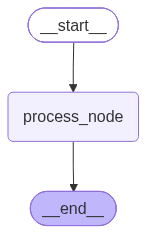

In [8]:
from IPython.display import Image, display
display(Image(agent.get_graph().draw_mermaid_png()))

In [12]:
conversation_history = []

user_input = input("Enter: ")
while user_input != "exit":
  conversation_history.append(HumanMessage(content=user_input))
  result = agent.invoke({"messages": conversation_history})
  conversation_history = result["messages"]
  user_input = input("Enter: ")


with open("logging.txt", "w") as file:
  file.write("Your Conversation Log:\n")

  for message in conversation_history:
    if isinstance(message, HumanMessage):
      file.write(f"You: {message.content}\n")
    elif isinstance(message, AIMessage):
      file.write(f"AI: {message.content}\n")
    else:
      file.write(f"Unknown message type: {message}\n")
  file.write("End of Conversation")

print("Conversation saved to logging.txt")



Enter: hi, how's the weather in bangalore

AI: [{'type': 'text', 'text': 'I don\'t have access to real-time weather data, so I can\'t provide the current conditions in Bangalore right now. \n\nTo get the live weather, temperature, and forecast, you can check a weather app on your phone, search **"weather in Bangalore"** on Google, or visit sites like [AccuWeather](https://www.accuweather.com) or [The Weather Channel](https://weather.com).', 'extras': {'signature': 'EswHCskHAWkUfROSJusQ9YJZMa6PULSzHpZTKq/XjJqwA08EaInLrQvqRXK0LGzngrLpBbr/xvPnuhNfktYwaTB2/2Iu/ws6TGHjOToW+5quF7UNTP+hrFquFY/JqTrytqg73cZQP9Vm6YyiS4yMwkjIS0QqSATM2ZCsrcB5WzhK6yJV3iLhW4YOE41aHBPQzR58KrqwsuqVEAUhIK0gsfx+l+DG5WAS8uyZJr4rNYzUEjy0LNXLWKTYJrKs8gx5T4u8harNBOmFqdEHsudX3Yzm9otjXzfohMSfJ6oEpBKq9WYsj+kxVpMC8z6o/hvbqLJ1uVbyVkXdMhT6xVAnguXOpjbBEIYn31WrFoqRUAuDEKn/kSlQG79e10OpJSvWDnLvzFeFutgEctbNIhw7HwNf1Yvp46lVDaKXQ49w8EPdmnNkSypyMMV1d3jbTgW0T/oH/VjwP8Fkm9lK6m0ibl6+Q1Yl8rI9nB9rJrK5ugzwSa1OD2c5OASUh06lo9oLxr8NEQAR8thheqG8pG